<a href="https://colab.research.google.com/github/priyansh-sood/cosc-hackweek-day2-challenge/blob/main/cats_vs_dog_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("moazeldsokyx/dogs-vs-cats")

print("Path to dataset files:", path)


100%|██████████| 817M/817M [00:06<00:00, 133MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/moazeldsokyx/dogs-vs-cats/versions/1


In [2]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level > 2:
        continue

    print("  " * level + os.path.basename(root) + "/")

    if level == 2:
        continue

    for file in files[:5]:
        print("  " * (level + 1) + file)

    if level == 0:
        print(f"Total files in root: {len(files)}")

1/
Total files in root: 0
  dataset/
    validation/
    train/
    test/


In [3]:
import os

for folder in ["train", "validation", "test"]:
    folder_path = os.path.join(path, "dataset", folder)

    print(f"\n{folder.upper()}")

    for item in os.listdir(folder_path):
        item_path = os.path.join(folder_path, item)

        if os.path.isdir(item_path):
            print(f"Folder: {item} | Images: {len(os.listdir(item_path))}")
        else:
            print(f"File: {item}")


TRAIN
Folder: dogs | Images: 10000
Folder: cats | Images: 10000

VALIDATION
Folder: dogs | Images: 2500
Folder: cats | Images: 2500

TEST
Folder: dogs | Images: 6219
Folder: cats | Images: 6242


In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


In [5]:
DATASET_PATH = os.path.join(path, "dataset")

train_dir = os.path.join(DATASET_PATH, "train")
val_dir = os.path.join(DATASET_PATH, "validation")
test_dir = os.path.join(DATASET_PATH, "test")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=True,
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["cats", "dogs"],
    shuffle=False
)

print("Class names:", train_ds.class_names)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Found 12461 files belonging to 2 classes.
Class names: ['cats', 'dogs']


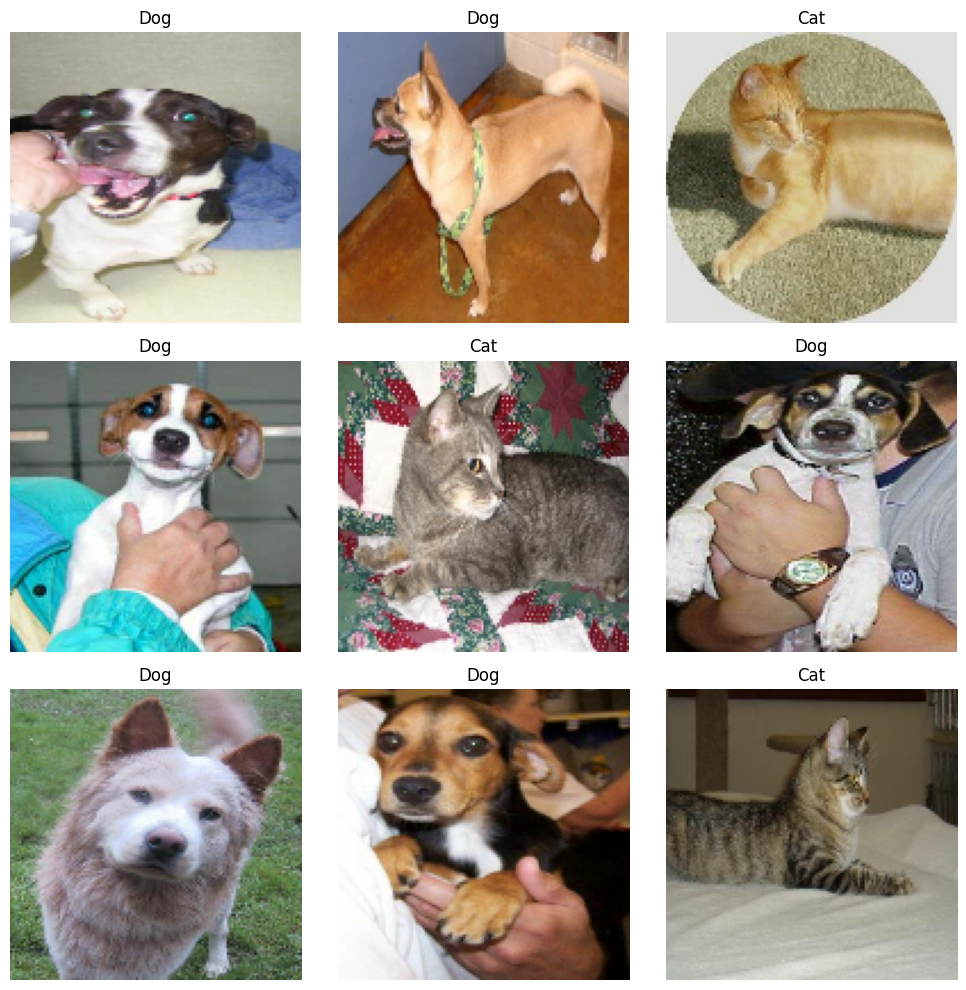

In [6]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        plt.title("Dog" if label == 1 else "Cat")

        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
model = keras.Sequential([
    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Classification layers
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Binary output: cat or dog
    layers.Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
159/625 ━━━━━━━━━━━━━━━━━━━━ 6:54 890ms/step - accuracy: 0.5222 - loss: 0.7366